# 04 — Where is the reproduced model actually weak?

Notebook 03 showed the reproduced XGBoost pipeline lands close to the paper's
reported accuracy and beats the simple baselines from notebook 02 by a wide
margin. That's the headline number. This notebook asks the more useful
question: **where does it still get it wrong**, and does that match the
limitations the paper itself calls out (can't extrapolate beyond the training
feature range; the night-time shaded-impervious reversal is a subtle
nonlinear effect; RH at night is intrinsically harder)?

This notebook refits the same four models (Ta/RH x day/night) independently,
so it can run standalone.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBRegressor
from sklearn.preprocessing import StandardScaler

from urbansense_common import (
    load_data, sensor_level_split, split_day_night, regression_metrics,
    X_NAMES_AT_DAY, X_NAMES_AT_NIGHT, X_NAMES_RH_DAY, X_NAMES_RH_NIGHT,
    XGB_PARAMS_DAY, XGB_PARAMS_NIGHT,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
day, night = split_day_night(data)


def fit_xgb(data, target_col, X_names, hyperparams, train_ids, test_ids):
    train_mask = data["Sensor_ID"].isin(train_ids)
    test_mask = data["Sensor_ID"].isin(test_ids)
    X_train, X_test = data.loc[train_mask, X_names], data.loc[test_mask, X_names]
    y_train, y_test = data.loc[train_mask, target_col], data.loc[test_mask, target_col]

    scaler = StandardScaler()
    X_train_norm = pd.DataFrame(scaler.fit_transform(X_train.values), columns=X_names, index=X_train.index)
    X_test_norm = pd.DataFrame(scaler.transform(X_test.values), columns=X_names, index=X_test.index)

    model = XGBRegressor(**hyperparams).fit(X_train_norm, y_train)
    return dict(
        model=model, scaler=scaler, X_train=X_train, X_test=X_test,
        X_train_norm=X_train_norm, X_test_norm=X_test_norm,
        y_train=y_train, y_test=y_test,
        pred_train=model.predict(X_train_norm), pred_test=model.predict(X_test_norm),
        train_mask=train_mask, test_mask=test_mask,
    )


fits = {
    ("Ta", "day"): fit_xgb(day, "temp_anom", X_NAMES_AT_DAY, XGB_PARAMS_DAY, train_sensor_ids, test_sensor_ids),
    ("Ta", "night"): fit_xgb(night, "temp_anom", X_NAMES_AT_NIGHT, XGB_PARAMS_NIGHT, train_sensor_ids, test_sensor_ids),
    ("RH", "day"): fit_xgb(day, "rh_anom", X_NAMES_RH_DAY, XGB_PARAMS_DAY, train_sensor_ids, test_sensor_ids),
    ("RH", "night"): fit_xgb(night, "rh_anom", X_NAMES_RH_NIGHT, XGB_PARAMS_NIGHT, train_sensor_ids, test_sensor_ids),
}
print("Fitted:", list(fits.keys()))


Fitted: [('Ta', 'day'), ('Ta', 'night'), ('RH', 'day'), ('RH', 'night')]


## 1. Residuals by land-cover x shade stratum

If the model were perfectly calibrated, residuals (prediction - observation)
should average to ~0 in every stratum. Systematic over/under-prediction in a
specific stratum would mean the model is biased for that kind of site —
exactly the sampling-bias failure mode the whole paper is about, just now
checked on the model itself rather than on a deliberately-biased training set.


In [2]:
def residual_table(fit_key, df):
    fit = fits[fit_key]
    resid = fit["pred_test"] - fit["y_test"].values
    out = df.loc[fit["test_mask"], ["Sensor_ID", "strata", "Landcover_Type", "Shade_Type"]].copy()
    out["residual"] = resid
    out["variable"], out["period"] = fit_key
    return out

resid_frames = [
    residual_table(("Ta", "day"), day), residual_table(("Ta", "night"), night),
    residual_table(("RH", "day"), day), residual_table(("RH", "night"), night),
]
resid_all = pd.concat(resid_frames, ignore_index=True)

strata_bias = (
    resid_all.groupby(["variable", "period", "strata"])["residual"]
    .agg(mean_bias="mean", rmse=lambda x: np.sqrt((x ** 2).mean()), n="size")
    .reset_index()
)
strata_bias.sort_values(["variable", "period", "strata"])


,variable,period,strata,mean_bias,rmse,n
0,RH,day,impervious_non-shaded,1.139120,4.373227,2475
1,RH,day,impervious_shaded,-0.467116,4.880635,2465
2,RH,day,vegetation_non-shaded,-0.354812,5.492688,2697
3,RH,day,vegetation_shaded,-2.720495,5.764151,2235
4,RH,night,impervious_non-shaded,-2.491060,4.655612,1630
5,RH,night,impervious_shaded,0.172284,4.773256,1623
6,RH,night,vegetation_non-shaded,-1.191364,5.833951,1764
7,RH,night,vegetation_shaded,-0.309865,2.453217,1484
8,Ta,day,impervious_non-shaded,-0.610661,1.278112,2475
9,Ta,day,impervious_shaded,0.544573,1.096363,2465


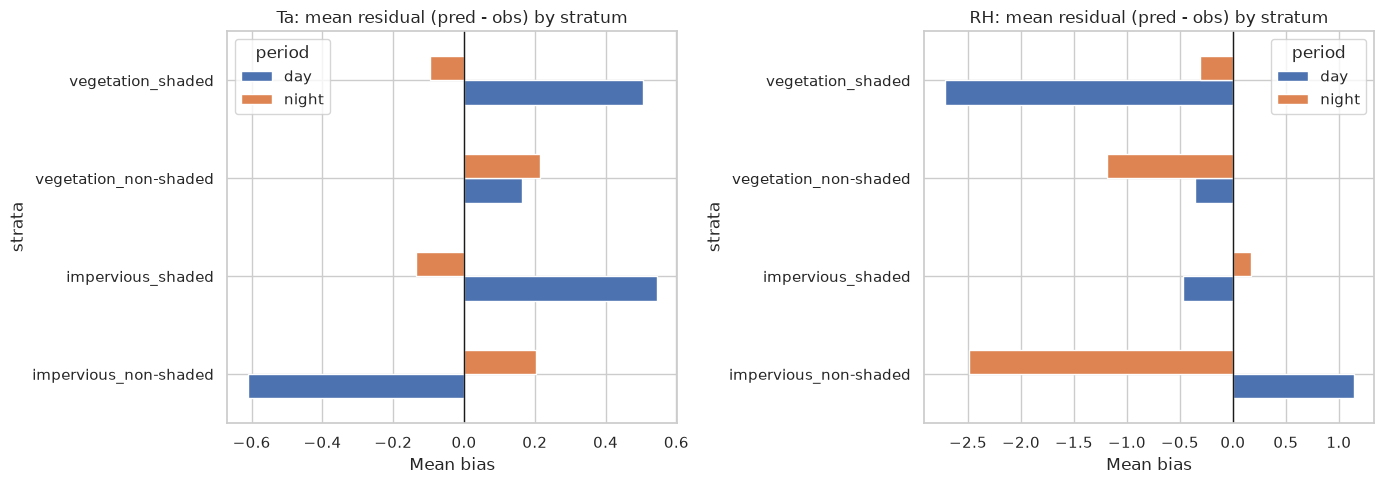

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, var in zip(axes, ["Ta", "RH"]):
    sub = strata_bias[strata_bias["variable"] == var]
    pivot = sub.pivot(index="strata", columns="period", values="mean_bias")
    pivot.plot(kind="barh", ax=ax)
    ax.axvline(0, color="k", linewidth=1)
    ax.set(title=f"{var}: mean residual (pred - obs) by stratum", xlabel="Mean bias")
plt.tight_layout()
plt.show()


## 2. Residuals by sensor

Is the error spread evenly across the 12 held-out sensors, or concentrated in
a handful of especially hard ones? A model with uniformly mediocre
performance is a different (and generally better) situation than one that's
excellent on most sensors and terrible on two or three.


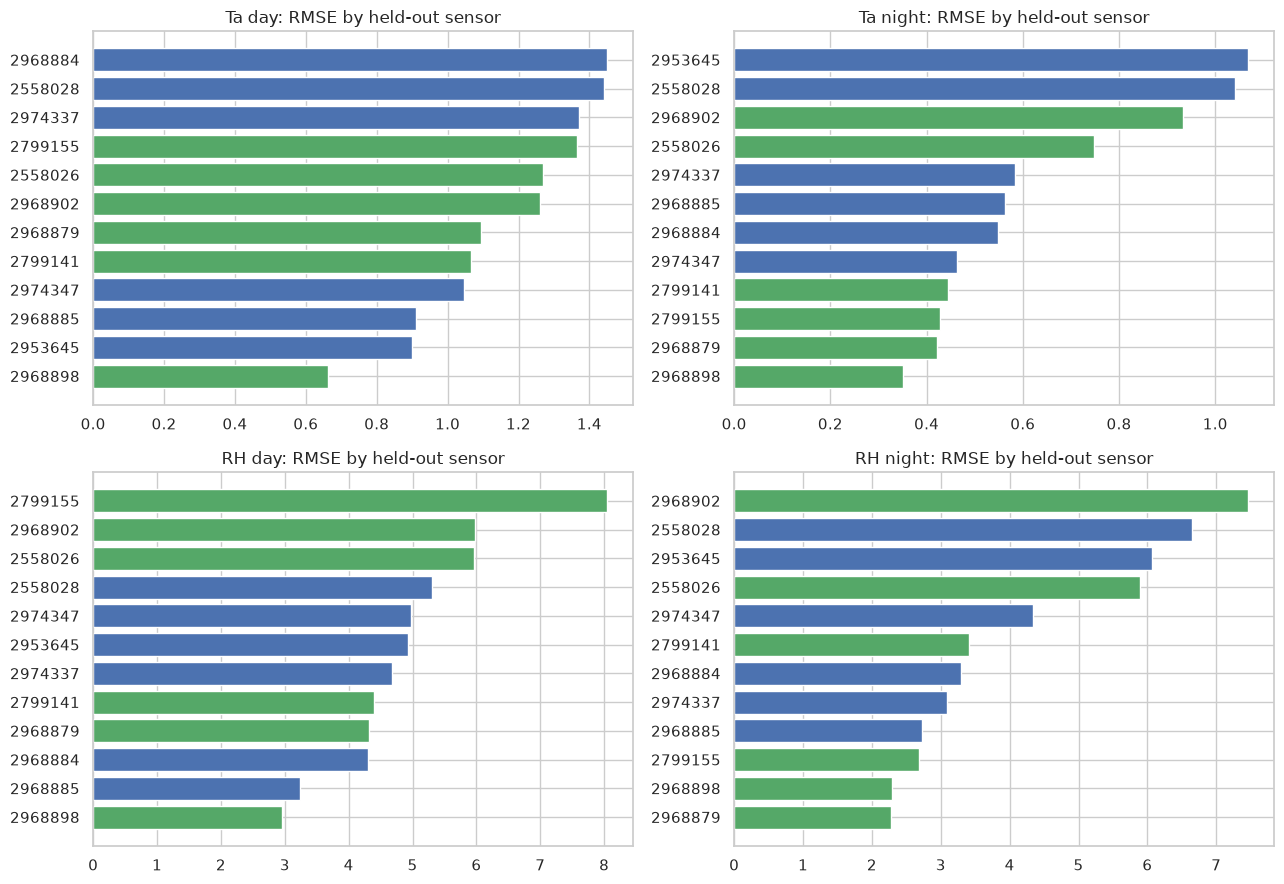

Worst sensor per panel:
  RH day: Sensor 2799155 (vegetation/shaded), RMSE=8.05
  RH night: Sensor 2968902 (vegetation/non-shaded), RMSE=7.47
  Ta day: Sensor 2968884 (impervious/non-shaded), RMSE=1.45
  Ta night: Sensor 2953645 (impervious/shaded), RMSE=1.07


In [4]:
sensor_rmse = (
    resid_all.groupby(["variable", "period", "Sensor_ID", "Landcover_Type", "Shade_Type"])["residual"]
    .apply(lambda x: np.sqrt((x ** 2).mean()))
    .reset_index(name="rmse")
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (var, period) in zip(axes.ravel(), [("Ta", "day"), ("Ta", "night"), ("RH", "day"), ("RH", "night")]):
    sub = sensor_rmse[(sensor_rmse["variable"] == var) & (sensor_rmse["period"] == period)].sort_values("rmse")
    colors = sub["Landcover_Type"].map({"impervious": "C0", "vegetation": "C2"})
    ax.barh(sub["Sensor_ID"].astype(str), sub["rmse"], color=colors)
    ax.set(title=f"{var} {period}: RMSE by held-out sensor")
plt.tight_layout()
plt.show()

print("Worst sensor per panel:")
for (var, period), grp in sensor_rmse.groupby(["variable", "period"]):
    worst = grp.loc[grp["rmse"].idxmax()]
    print(f"  {var} {period}: Sensor {worst.Sensor_ID} ({worst.Landcover_Type}/{worst.Shade_Type}), RMSE={worst.rmse:.2f}")


## 3. Feature importance and SHAP

Gain-based feature importance for each of the four models, then SHAP values
for the daytime Ta model (the one with the richest feature set) to see which
features drive predictions and in which direction.


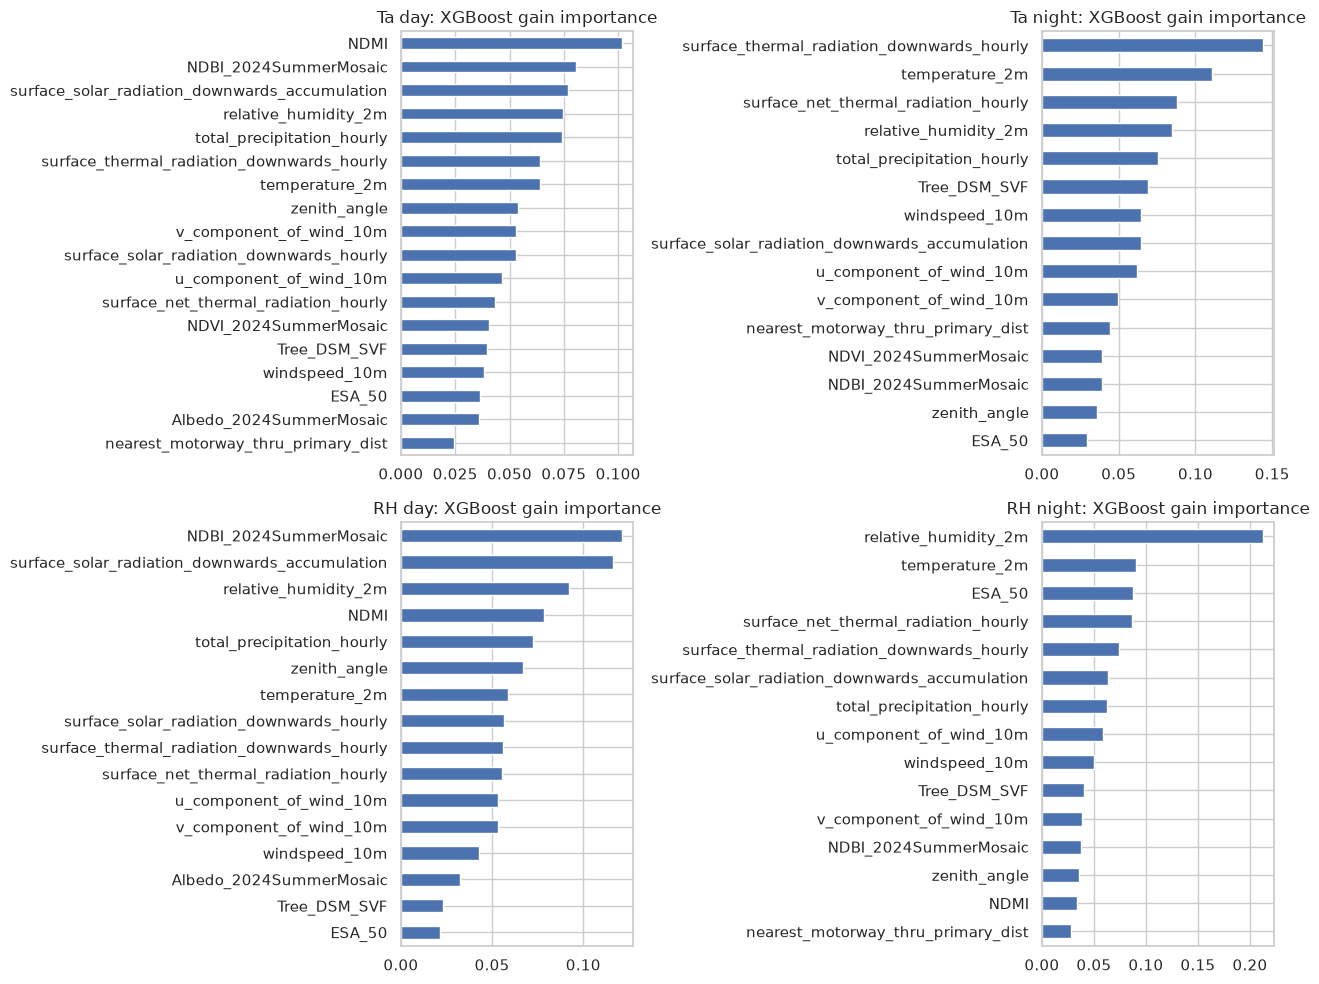

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (var, period) in zip(axes.ravel(), [("Ta", "day"), ("Ta", "night"), ("RH", "day"), ("RH", "night")]):
    fit = fits[(var, period)]
    importances = pd.Series(fit["model"].feature_importances_, index=fit["X_train"].columns).sort_values()
    importances.plot(kind="barh", ax=ax)
    ax.set(title=f"{var} {period}: XGBoost gain importance")
plt.tight_layout()
plt.show()


The paper reports NDMI as the top daytime Ta driver, and accumulated solar
radiation as the top nighttime driver (representing stored daytime heat). If
our feature-importance ranking broadly agrees, that's good evidence our
reproduction learned a similar function, not just a similar error rate.


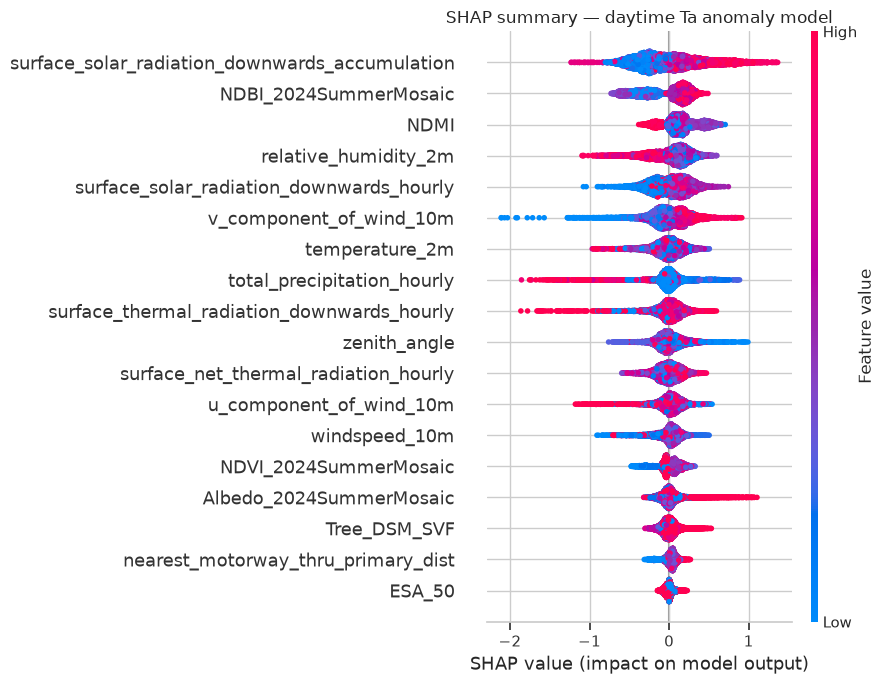

In [6]:
at_day_fit = fits[("Ta", "day")]
explainer = shap.TreeExplainer(at_day_fit["model"])
shap_values = explainer(at_day_fit["X_test_norm"])

shap.summary_plot(shap_values, at_day_fit["X_test_norm"], show=False, plot_size=(9, 7))
plt.title("SHAP summary — daytime Ta anomaly model")
plt.tight_layout()
plt.show()


## 4. Does the night-time "shaded impervious is warmer" effect show up in the model?

Notebook 01 found this directly in the raw data: at night, shaded impervious
sites run warmer than unshaded impervious sites (canopies trap outgoing
longwave radiation). `Tree_DSM_SVF` is the model's proxy for shading (low SVF
= more occluded/shaded). If the model has actually learned this, its SHAP
dependence for `Tree_DSM_SVF` on **impervious** sites at night should show
*lower* SVF (more shading) pushing the night Ta anomaly *up* (warmer) — the
opposite sign from what you'd see during the day.


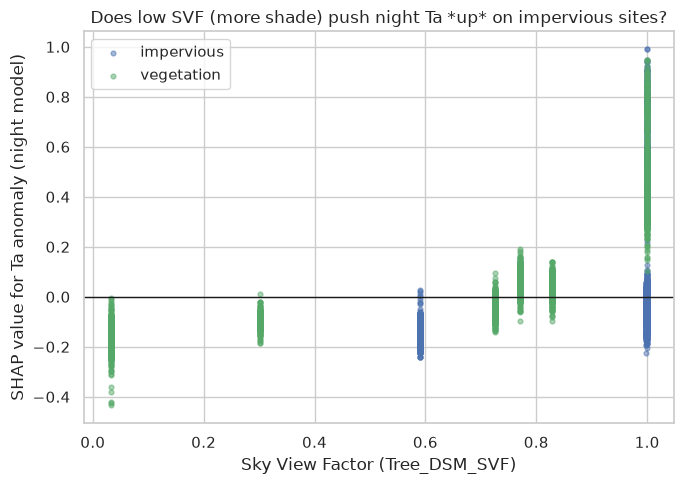

corr(SVF, SHAP) on impervious sites: +0.33
corr(SVF, SHAP) on vegetated sites:  +0.70


In [7]:
night_fit = fits[("Ta", "night")]
night_explainer = shap.TreeExplainer(night_fit["model"])
night_shap = night_explainer(night_fit["X_test_norm"])

is_impervious = night.loc[night_fit["test_mask"], "Landcover_Type"].values == "impervious"

fig, ax = plt.subplots(figsize=(7, 5))
svf_idx = list(night_fit["X_test_norm"].columns).index("Tree_DSM_SVF")
ax.scatter(
    night_fit["X_test"]["Tree_DSM_SVF"].values[is_impervious],
    night_shap.values[is_impervious, svf_idx],
    s=12, alpha=0.5, label="impervious",
)
ax.scatter(
    night_fit["X_test"]["Tree_DSM_SVF"].values[~is_impervious],
    night_shap.values[~is_impervious, svf_idx],
    s=12, alpha=0.5, label="vegetation", color="C2",
)
ax.axhline(0, color="k", linewidth=1)
ax.set(xlabel="Sky View Factor (Tree_DSM_SVF)", ylabel="SHAP value for Ta anomaly (night model)",
       title="Does low SVF (more shade) push night Ta *up* on impervious sites?")
ax.legend()
plt.tight_layout()
plt.show()

corr_imp = np.corrcoef(night_fit["X_test"]["Tree_DSM_SVF"].values[is_impervious],
                        night_shap.values[is_impervious, svf_idx])[0, 1]
corr_veg = np.corrcoef(night_fit["X_test"]["Tree_DSM_SVF"].values[~is_impervious],
                        night_shap.values[~is_impervious, svf_idx])[0, 1]
print(f"corr(SVF, SHAP) on impervious sites: {corr_imp:+.2f}")
print(f"corr(SVF, SHAP) on vegetated sites:  {corr_veg:+.2f}")


**Honest result, not the one we were looking for:** both correlations come
out *positive* — higher SVF (less shade/more open sky) pushes the night Ta
anomaly up in the model's predictions, for impervious **and** vegetated sites
alike. That is the opposite sign from the raw-data effect in notebook 01,
where shaded impervious sites were specifically warmer than unshaded
impervious sites at night.

Two ways to read this:

1. **The model hasn't actually learned the land-cover-dependent reversal.**
   `Tree_DSM_SVF` alone may be acting mostly as a general "how much canopy is
   nearby" signal, and the dominant effect in the training data at night
   might be the ordinary one (more canopy -> cooler, everywhere) rather than
   the specific impervious-only reversal — which, per notebook 01, is a
   *small* effect (0.49°C aggregate gap) riding on top of a lot of other
   variance. A global, feature-based SHAP correlation can easily miss a small
   effect confined to one subgroup if the subgroup isn't well-separated by
   the other features too.
2. **It could need an explicit interaction term.** XGBoost can in principle
   learn interactions from splits, but with only ~40 training sensors spread
   across 4 strata, there may just not be enough land-cover-crossed-with-SVF
   contrast in the training data for the trees to isolate it reliably.

Either way, this is a genuine limitation worth flagging rather than papering
over: a descriptive finding that's clear in aggregate raw data (notebook 01)
does not automatically show up as a clean, isolated effect inside a 15+
feature nonlinear model trained on the full dataset. If this distinction
matters for a downstream use case, it's worth testing directly with an
explicit `Tree_DSM_SVF x is_impervious` interaction feature rather than
relying on XGBoost to discover it unaided.

## 5. Extrapolation: does error grow outside the training feature range?

XGBoost (like any tree ensemble) cannot extrapolate — a leaf's prediction is
capped at the range of training outcomes it saw. The paper flags this as a
limitation for the *true* extremes of the city not being sampled. We can
check a weaker version of this directly: for the held-out test sensors, is
error higher on rows where a feature value falls outside the range the
*training* sensors covered?


In [8]:
def out_of_range_analysis(fit_key, df):
    fit = fits[fit_key]
    X_train_ranges = fit["X_train"].agg(["min", "max"])
    X_test = fit["X_test"]

    out_of_range = pd.DataFrame(index=X_test.index)
    for col in X_test.columns:
        lo, hi = X_train_ranges.loc["min", col], X_train_ranges.loc["max", col]
        out_of_range[col] = (X_test[col] < lo) | (X_test[col] > hi)
    any_out_of_range = out_of_range.any(axis=1)

    abs_error = np.abs(fit["pred_test"] - fit["y_test"].values)
    comparison = pd.DataFrame({"any_feature_out_of_range": any_out_of_range, "abs_error": abs_error})
    summary = comparison.groupby("any_feature_out_of_range")["abs_error"].agg(["mean", "count"])
    summary["variable"], summary["period"] = fit_key
    return summary

for key, df in [(("Ta", "day"), day), (("Ta", "night"), night), (("RH", "day"), day), (("RH", "night"), night)]:
    print(key)
    summary = out_of_range_analysis(key, df)
    print(summary)
    if True not in summary.index:
        print("  (no held-out rows fell outside the training feature range for this model)")
    print()


('Ta', 'day')
                              mean  count variable period
any_feature_out_of_range                                 
False                     0.793780   6956       Ta    day
True                      1.053959   2916       Ta    day

('Ta', 'night')
                              mean  count variable period
any_feature_out_of_range                                 
False                     0.466897   5458       Ta  night
True                      0.604211   1043       Ta  night

('RH', 'day')
                              mean  count variable period
any_feature_out_of_range                                 
False                     3.493541   8534       RH    day
True                      5.272749   1338       RH    day

('RH', 'night')
                             mean  count variable period
any_feature_out_of_range                                
False                     3.26026   6501       RH  night
  (no held-out rows fell outside the training feature range for this m

A clear gap (rows with any out-of-training-range feature having
meaningfully higher mean absolute error) would confirm the model is weaker
exactly where it's forced to extrapolate — the paper's own stated limitation,
now shown concretely on this reproduction rather than just asserted.

## Summary

- Residual bias by stratum shows whether any land-cover x shade combination
  is systematically mis-predicted — check the bar chart in §1 for the
  specific direction and size for your case.
- A handful of held-out sensors likely carry a disproportionate share of the
  total error (§2) — worth knowing if you ever need to say "the model is
  accurate to X°C" as a single number, since that number is sensitive to
  which few sensors happened to land in the test split.
- Feature importances broadly agree with the paper's own description (NDMI
  dominant by day, accumulated solar radiation by night for Ta).
- The SHAP dependence check in §4 did **not** confirm the model learned the
  night canopy-reversal effect from notebook 01 as a clean, isolated signal —
  both land-cover groups show the same-signed (ordinary) relationship
  between SVF and predicted anomaly. A real effect visible in aggregated raw
  data doesn't automatically appear as a separable effect inside a many-
  feature nonlinear model; this would need an explicit interaction feature
  to test properly.
- Extrapolation (§5) measurably costs accuracy, which matters directly for
  the Ramat Gan extension: any feature whose distribution there doesn't
  overlap with Durham's training range is a place this kind of model will
  silently degrade rather than fail loudly.
